# Introdução

<div style="text-align: justify;">

A indústria vinícola possui grande relevância econômica e cultural em diversos países. Tradicionalmente, a avaliação da qualidade de um vinho é realizada por especialistas, por meio de análises sensoriais, que consideram aspectos como aroma, sabor, acidez e equilíbrio. No entanto, esse processo pode ser subjetivo e demandar tempo, além de depender da experiência dos avaliadores.

<p>Com o avanço das técnicas de ciência de dados e aprendizado de máquina, tornou-se possível utilizar dados físico-químicos obtidos durante a produção do vinho para auxiliar na previsão da qualidade final do produto. Dessa forma, modelos preditivos podem apoiar enólogos e produtores na tomada de decisão, permitindo ajustes no processo produtivo e contribuindo para a padronização da qualidade.</p>

<p>O dataset utilizado possui informações de propriedades físico-químicas de diversas amostras de vinhos. Esses dados foram analisados, tratados e utilizados para o desenvolvimento de modelos preditivos capazes de prever a qualidade de um vinho a partir de suas características.</p>

</div>

### Atributos:

- **Acidez fixa:** Representa os principais ácidos não voláteis presentes no vinho, contribuindo para seu sabor ácido, frescor e equilíbrio.

- **Acidez volátil:** Está relacionada principalmente ao ácido acético. Em níveis elevados, pode causar aromas e sabores desagradáveis, semelhantes a vinagre.

- **Ácido cítrico:** Ácido naturalmente presente nas uvas e no vinho. Contribui para a acidez, frescor e equilíbrio da bebida.

- **Açúcar residual:** Quantidade de açúcar que permanece no vinho após a fermentação. Influencia diretamente sua doçura.

- **Cloretos:** Representam a quantidade de sais, principalmente cloretos, presentes no vinho. Em concentrações elevadas podem contribuir para um sabor salgado ou desagradável.

- **Dióxido de enxofre livre:** Quantidade de SO₂ disponível para atuar como conservante e antioxidante, ajudando a proteger o vinho contra oxidação e microrganismos.

- **Dióxido de enxofre total:** Soma do dióxido de enxofre livre e do dióxido de enxofre ligado a outros componentes do vinho.

- **Densidade:** Relação entre a massa e o volume do vinho. Pode ser influenciada principalmente pela quantidade de álcool e açúcar presentes na bebida.

- **pH:** Indica o nível de acidez do vinho. Valores menores representam maior acidez, enquanto valores maiores indicam menor acidez. O pH influencia o sabor, a estabilidade e a conservação do vinho.

- **Sulfatos:** Compostos presentes no vinho que podem contribuir para a conservação e para determinadas características sensoriais, além de influenciarem a percepção de sabor.

- **Álcool:** Percentual de etanol presente no vinho. Influencia o corpo, a sensação de calor e o equilíbrio geral da bebida.

- **Qualidade:** Nota atribuída ao vinho, utilizada como variável de avaliação da qualidade geral da bebida.

- **Identificador:** Código utilizado para identificar individualmente cada registro do conjunto de dados.

# Análise exploratória dos dados

## Importação das Bibliotecas e Construção do DataFrame

In [ ]:
# Bibliotecas utilizadas para análise exploratória dos dados e modelagem

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Montar o DataFrame

df = pd.read_csv('WineQT.csv', sep = ',')
df.head(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1


## Análise Preliminar

In [ ]:
# Informações do DataFrame

print('Quantidade de registros no dataset:', df.shape[0], 'linhas e', df.shape[1], 'colunas.')
print('\nInformações das Colunas:\n')
df.info()

Quantidade de registros no dataset: 1143 linhas e 13 colunas.

Informações das Colunas:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory us

<p style="text-align: justify;">
Remove-se a Coluna "ID", pois ela apresenta apenas um caráter de identificação, compromentendo a percepção de dados duplicados.
</p>

In [ ]:
# Remover a váriável ID

df_vinhos_sem_id = df.drop('Id', axis = 1)
df_vinhos_sem_id.head(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5


In [ ]:
# Verificar a existência de dados duplicados

print('Quantidade dados duplicados:', df_vinhos_sem_id.duplicated().sum())

# Verificar a existência de dados nulos

print('\nDados Nulos:')
df_vinhos_sem_id.isnull().sum()

Quantidade dados duplicados: 125

Dados Nulos:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
# Remover registros duplicados, que podem gerar impactos futuros

df_vinhos = df_vinhos_sem_id.drop_duplicates().reset_index(drop=True)

# Verificar se a remoção foi feita de forma correta

status = "OK" if len(df_vinhos) == len(df) - df_vinhos_sem_id.duplicated().sum() else "Erro na contagem"
print("Registros após a remoção:", len(df_vinhos), f"({status})")

Registros após a remoção: 1018 (OK)


## <h2>Visão geral do conjunto de dados</h2>

O dataset original contém **1.143 registros e 13 colunas**.

Não foram identificados valores Nulos.

Foi feita a remoção da coluna `ID` e posteriormente foi feita a análise de registros duplicados. Desta análise foram identificados 125 linhas em repetição.

Como o objetivo é criar modelos preditivos de qualidade de vinhos utilizando este dataset, foram removidos os dados repetidos, e mantidos apenas as primeiras ocorrências, já que a presença de repetições pode enviesar os modelos.

Após a remoção das repetições, o dataset ficou com **1018** registros para serem analisados, tratados e utilizados nos modelos preditivos.


# Análise da distribuição dos vinhos por qualidade

In [ ]:
# Máximo e mínimo da qualidade

print("Nota Miníma de Qualidade:", df_vinhos["quality"].min())
print("Nota Máxima de Qualidade:", df_vinhos["quality"].max())

Nota Miníma de Qualidade: 3
Nota Máxima de Qualidade: 8


In [ ]:
# Quantidade absoluta e percentual de vinhos por nota de qualidade

df_vinhos_por_qualidade = df_vinhos['quality'].value_counts().sort_index().to_frame('quantidade')
df_vinhos_por_qualidade['percentual'] = (df_vinhos_por_qualidade['quantidade'] / len(df_vinhos) * 100).round(2)
df_vinhos_por_qualidade

,quantidade,percentual
quality,,
3,6,0.59
4,33,3.24
5,433,42.53
6,409,40.18
7,122,11.98
8,15,1.47


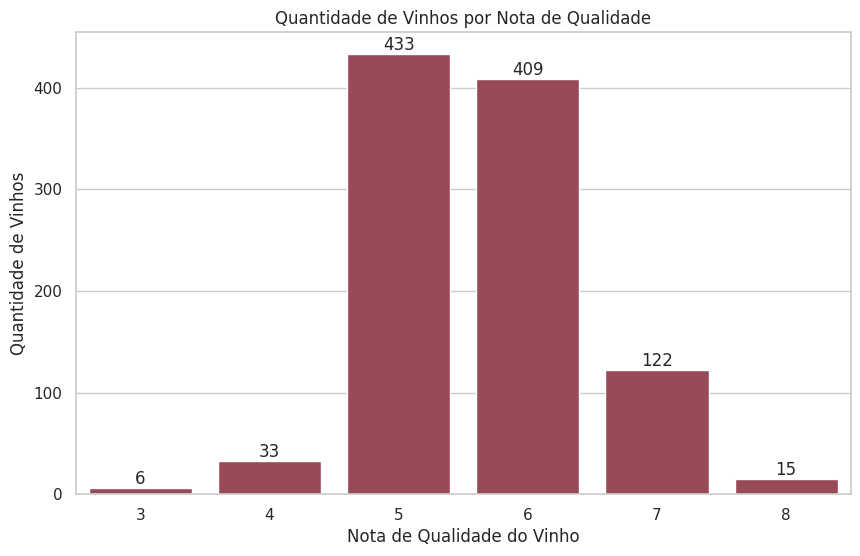

In [ ]:
# Construção do Gráfico da Quantidade de Vinhos por Nota de Qualideade, para melhorar a visualização destes dados

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data = df_vinhos_por_qualidade, x = 'quality', y = 'quantidade', color="#A63D50")
ax.bar_label(ax.containers[0])
plt.xlabel('Nota de Qualidade do Vinho')
plt.ylabel('Quantidade de Vinhos')
plt.title('Quantidade de Vinhos por Nota de Qualidade')
plt.show()


O gráfico evidencia maior concentração de vinhos com notas 5 e 6. Em contrapartida, vinhos com notas superiores (7 e 8) correspondem a apenas 137 entradas de nossa base. Essa distribuição indica um desbalanceamento entre as classes, aspecto importante para as etapas de classificação e avaliação dos modelos de Machine Learning, especialmente na identificação de vinhos de alta qualidade.

Uma forma de aprimorar esta visualização, e deixá-la ainda mais evidente, é separar nossos vinhos nas categorias "Alta Qualidade" e "Baixa/Média Qualidade".

In [ ]:
# Atribuir valores binários a qualidade dos vinhos

df_vinhos["alta_qualidade"] = (df_vinhos["quality"] >= 7).astype(int)

display(df_vinhos.head(2))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,alta_qualidade
0,7.4,0.70,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0


In [ ]:
# Calcular a porcentagem de vinhos por categoria

total_vinhos = len(df_vinhos)

alta_qualidade = (df_vinhos['quality'] >= 7).sum()
baixa_media_qualidade = (df_vinhos['quality'] < 7).sum()

percentuais = [baixa_media_qualidade / total_vinhos * 100, alta_qualidade / total_vinhos * 100]

print(f"Vinhos de Baixa/média qualidade: {percentuais[0]:.2f}%")
print(f"\nVinhos de Alta qualidade: {percentuais[1]:.2f}%")

Vinhos de Baixa/média qualidade: 86.54%

Vinhos de Alta qualidade: 13.46%


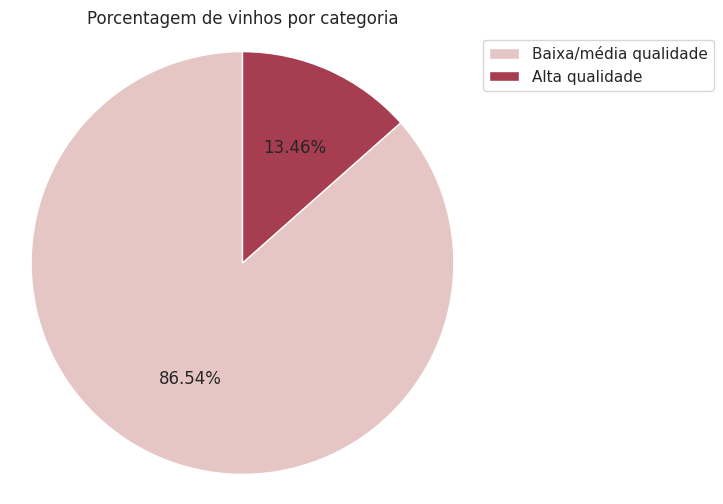

In [ ]:
# Criando um gráfico de pizza para melhor visualização destes dados

labels = ['Baixa/média qualidade', 'Alta qualidade']
colors = ["#E6C5C5", "#A63D50"]

figura, grafico = plt.subplots(figsize=(6, 6))

grafico.pie(percentuais, autopct='%1.2f%%', colors=colors, startangle = 90)

grafico.axis('equal')
plt.title('Porcentagem de vinhos por categoria')
plt.legend(labels, loc='upper left', bbox_to_anchor = (1, 1))

plt.show()

**Distribuição da qualidade dos vinhos**

As notas de qualidade variam de 3 a 8.

Foi criada uma nova coluna que dividiu os vinhos analisados em:

- **Baixa/média qualidade (0):** notas inferiores a 7.
- **Alta qualidade (1):** notas iguais ou superiores a 7.

A distribuição de vinhos dentro dessas categorias é:
- Baixa/média qualidade: Mais de 86% dos vinhos;
- Alta Qualidade: 13,46% dos vinhos;

Desta maneira, a distribuição demonstra desequilíbrio entre as classes, com predominância dos vinhos de baixa/média qualidade.

## Análise das Demais Categorias

In [ ]:
# Descrição das categorias

df_vinhos.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.289,1.741,4.600,7.100,7.900,9.100,15.900
volatile acidity,1018.0,0.534,0.183,0.120,0.390,0.520,0.645,1.580
citric acid,1018.0,0.269,0.196,0.000,0.090,0.250,0.420,1.000
residual sugar,1018.0,2.524,1.315,0.900,1.900,2.200,2.600,15.500
chlorides,1018.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1018.0,15.649,10.177,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1018.0,46.326,33.124,6.000,21.000,38.000,62.000,289.000
density,1018.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1018.0,3.312,0.158,2.740,3.210,3.310,3.400,4.010
sulphates,1018.0,0.657,0.168,0.330,0.550,0.620,0.720,2.000


Esta análise revela diferenças entre os valores máximos e os quartis superiores de algumas variáveis. Tornando necessária uma investigação mais detalhada quanto a presença de Outliers.

## Visualização de possíveis outliers nas colunas que apresentaram discrepância

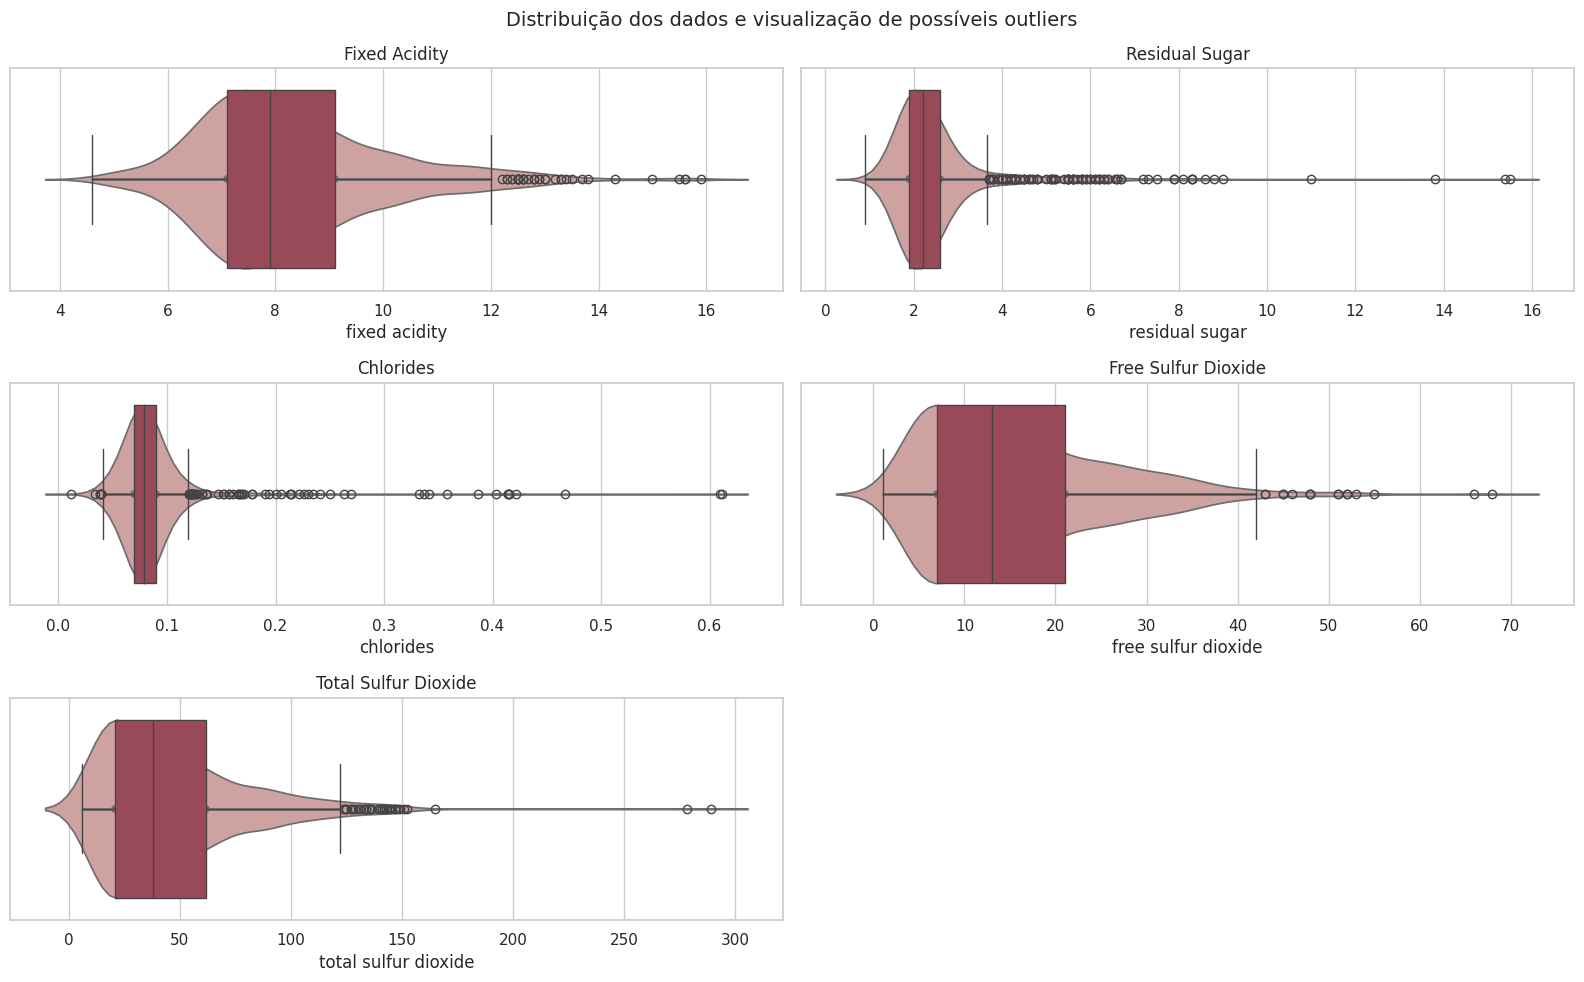

In [ ]:
# Gráficos de boxplot e violino para visualização de possíveis outliers

fig, axes = plt.subplots(3, 2, figsize=(16, 10))

colunas = ["fixed acidity", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide"]

titulos = ["Fixed Acidity", "Residual Sugar", "Chlorides", "Free Sulfur Dioxide", "Total Sulfur Dioxide"]

for ax, coluna, titulo in zip(axes.flat, colunas, titulos):
    sns.violinplot(x=coluna, data=df_vinhos, ax=ax, color="#D69A9A")
    sns.boxplot(x=coluna, data=df_vinhos, ax=ax, whis=1.5, color="#A63D50")
    ax.set_title(titulo)

fig.suptitle("Distribuição dos dados e visualização de possíveis outliers", fontsize=14)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
features = df_vinhos.drop(columns=["quality", "alta_qualidade"]).columns.tolist()

outlier_summary = []

# Identificação de possíveis outliers pelo método IQR
# Valores fora dos limites são sinalizados, não removidos

for column in features:

    Q1 = df_vinhos[column].quantile(0.25)
    Q3 = df_vinhos[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((df_vinhos[column] < lower_bound) | (df_vinhos[column] > upper_bound))

    outlier_summary.append({
        "feature": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outliers": int(outliers.sum()),
        "percentage": outliers.mean() * 100})

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.sort_values("outliers", ascending=False).round(2))

,feature,lower_bound,upper_bound,outliers,percentage
3,residual sugar,0.85,3.65,95,9.33
4,chlorides,0.04,0.12,71,6.97
9,sulphates,0.30,0.97,41,4.03
0,fixed acidity,4.10,12.10,37,3.63
6,total sulfur dioxide,-40.50,123.50,33,3.24
7,density,0.99,1.00,30,2.95
8,pH,2.92,3.68,24,2.36
5,free sulfur dioxide,-14.00,42.00,16,1.57
1,volatile acidity,0.01,1.03,10,0.98
10,alcohol,6.95,13.75,6,0.59


## Análise de valores extremos

A análise descritiva revelou que as variáveis 'fixed acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide' e 'total sulfur dioxide' apresentaram valores máximos discrepantes em relação às suas médias. Diante disso, foram gerados gráficos de violino e boxplot para avaliar a distribuição dos dados e identificar possíveis outliers.

Os gráficos evidenciaram a presença de valores isolados muito acima do terceiro quartil (Q3), justificando as discrepâncias observadas. A partir do cálculo do intervalo interquartil (IQR), a variável 'residual sugar' apresentou o maior número de outliers (95), correspondendo a mais de 9% dos registros, enquanto 'citric acid' apresentou apenas um.

Optou-se por não remover os valores extremos do dataset, uma vez que não foram identificadas evidências de erros nos registros que justificassem sua exclusão.

# Análise de correlação entre as medidas e a qualidade dos vinhos

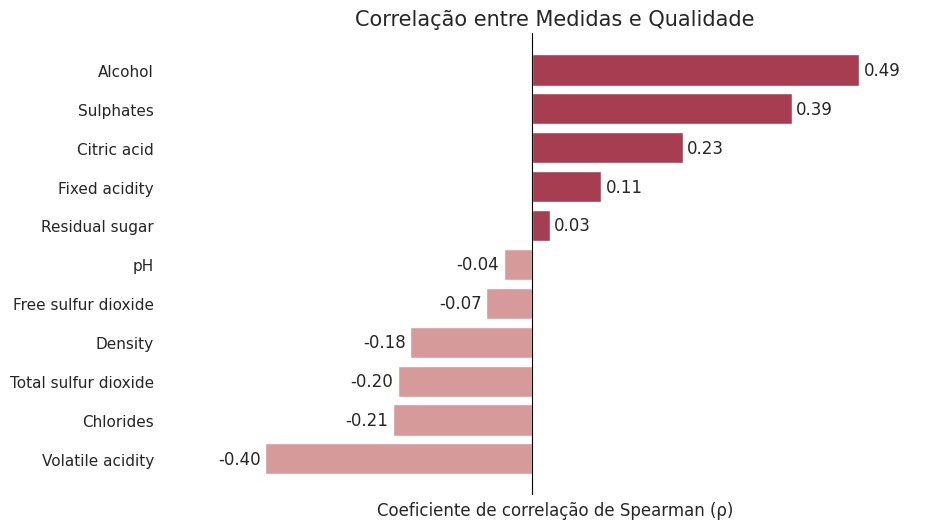

In [ ]:
# Gráfico de correlação com a qualidade pelo método spearman

correlacao = df_vinhos.corr(method="spearman")['quality'].drop(['quality', 'alta_qualidade']).sort_values()
correlacao.index = correlacao.index.str.capitalize()        # Transforma 'alcohol' em 'Alcohol'
correlacao = correlacao.rename(index={'Ph': 'pH'})          # Corrige Ph para pH.

cores = np.where(correlacao > 0, '#A63D50', '#D69A9A')

plt.figure(figsize=(10, 6))
barras = plt.barh(correlacao.index, correlacao.values, color=cores)
plt.bar_label(barras, fmt='%.2f', padding=3)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlação entre Medidas e Qualidade', fontsize=15)
plt.xlabel('Coeficiente de correlação de Spearman (ρ)')
plt.xlim(-0.55, 0.62)
plt.xticks([])
plt.grid(False)
sns.despine(left=True, bottom=True)
plt.show()

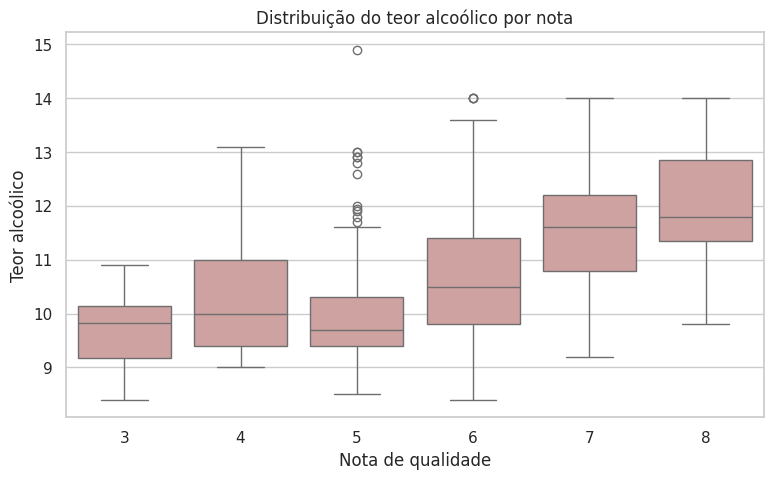

In [ ]:
# Comparação da distribuição do teor alcoólico por nota

plt.figure(figsize=(9, 5))

sns.boxplot(data=df_vinhos, x="quality", y="alcohol", color="#D69A9A")

plt.title("Distribuição do teor alcoólico por nota")
plt.xlabel("Nota de qualidade")
plt.ylabel("Teor alcoólico")
plt.show()

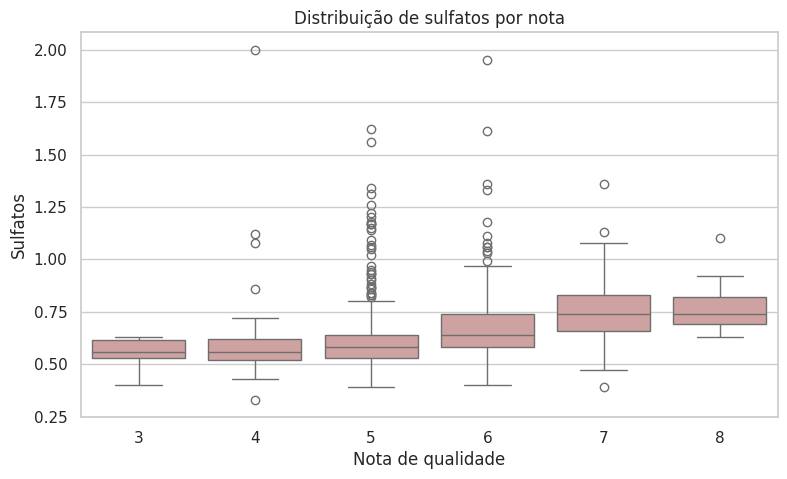

In [ ]:
# Comparação da distribuição de sulfatos por nota

plt.figure(figsize=(9, 5))

sns.boxplot(data=df_vinhos, x="quality", y="sulphates", color="#D69A9A")

plt.title("Distribuição de sulfatos por nota")
plt.xlabel("Nota de qualidade")
plt.ylabel("Sulfatos")
plt.show()

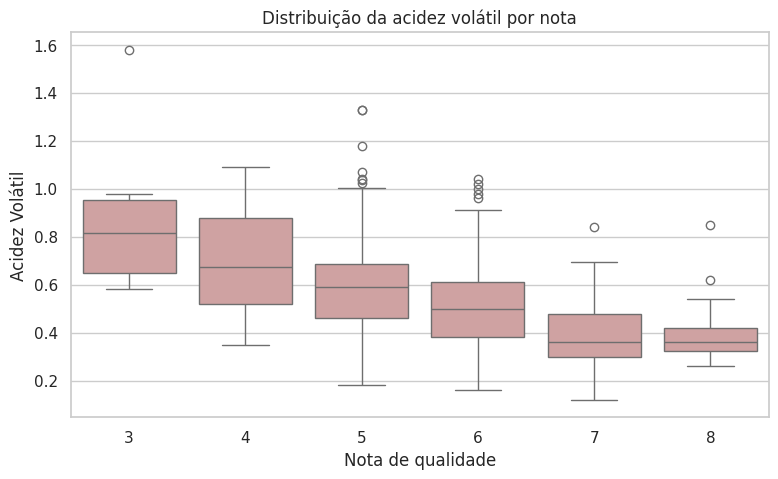

In [ ]:
# Comparação da distribuição de acidez volátil por nota

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_vinhos,
    x="quality",
    y="volatile acidity",
    color="#D69A9A"
)

plt.title("Distribuição da acidez volátil por nota")
plt.xlabel("Nota de qualidade")
plt.ylabel("Acidez Volátil")
plt.show()

### Análise de correlação entre as características físico-químicas e a qualidade dos vinhos

Para analisar a relação entre as características físico-químicas e a qualidade dos vinhos, foi utilizado o coeficiente de correlação de Spearman, método que permite identificar associações monotônicas entre variáveis, em que à medida que uma variável aumenta, a outra variável tende a sempre aumentar ou a sempre diminuir, mas não necessariamente de forma linear. O método foi escolhido por ser menos sensível a valores extremos e por não exigir que os dados apresentem distribuição normal.

A análise de correlação e dos gráficos permitiram identificar:

- O gráfico de barras horizontal mostrou que tanto o teor alcoólico ('alcohol') quanto os sulfatos ('sulphates') apresentaram associação positiva moderada com a nota de qualidade (0,49 e 0,39, respectivamente), tendo os vinhos de maiores notas apresentado tendência a ter maior teor de álcool e sulfatos. Porém, quando analisados os gráficos de boxplot, pode-se observar que existem vinhos de baixa/media qualidade que também apresentam valores mais altos de álcool e sulfatos;

- O gráfico de barras da variável acidez volátil ('volatile acidity') apresentou associação negativa moderada com a nota de qualidade (-0,4), que pode ser observado nos gráficos boxplot que mostram que os vinhos de maior qualidade tendem a ter menor acidez. No entanto, alguns vinhos classificados como de baixa/média qualidade também apresentaram menores quantidades de acidez volátil;  

- As sobreposições observadas nos gráficos de boxplot das variáveis analisadas indicam que estas não podem ser utilizadas isoladamente para determinar a qualidade do vinho;

As correlações identificadas representam associações estatísticas e não comprovam relações de causa e efeito.

Na base analisada, os vinhos de alta qualidade apresentaram, em média, maior teor alcoólico, menor acidez volátil e maior concentração de sulfatos.

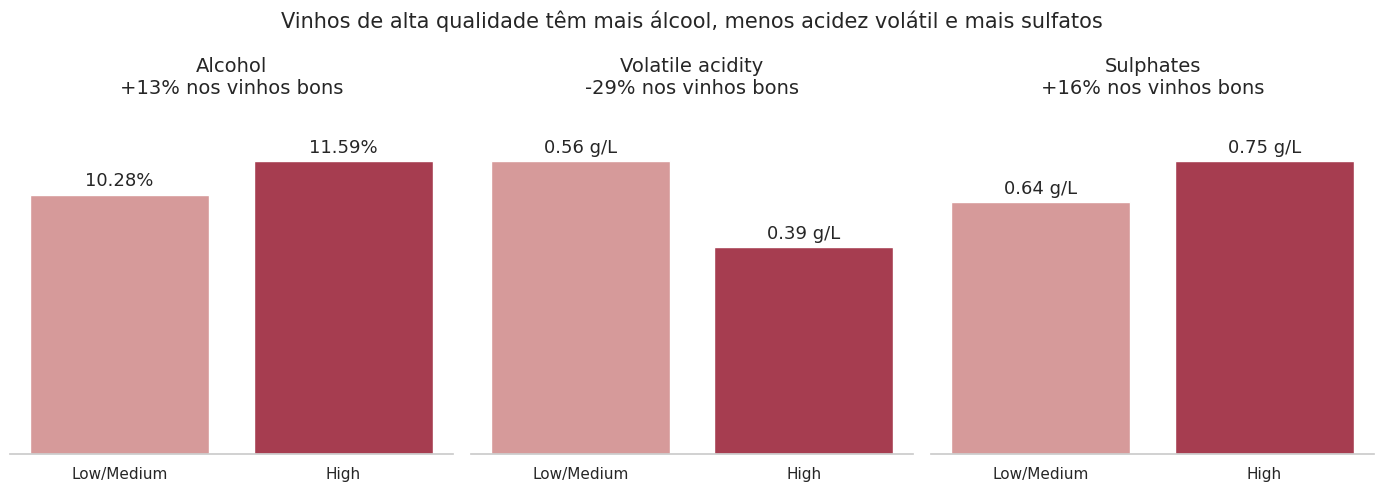

In [ ]:
# Verificando essas medidas lado a lado

medidas = ['alcohol', 'volatile acidity', 'sulphates']
titulos = ['Alcohol', 'Volatile acidity', 'Sulphates']
unidades = ['%', ' g/L', ' g/L']

fig, eixos = plt.subplots(1, 3, figsize=(14, 5))

for i in range(3):
    media_ruim = df_vinhos[df_vinhos['alta_qualidade'] == 0][medidas[i]].mean()
    media_bom = df_vinhos[df_vinhos['alta_qualidade'] == 1][medidas[i]].mean()

    # quanto o vinho bom tem a mais (ou a menos) que o ruim, em %
    diferenca = (media_bom - media_ruim) / media_ruim * 100

    barras = eixos[i].bar(['Low/Medium', 'High'], [media_ruim, media_bom], color=['#D69A9A', '#A63D50'])

    # número em cima da barra, agora com a unidade
    rotulos = [f'{media_ruim:.2f}{unidades[i]}', f'{media_bom:.2f}{unidades[i]}']
    eixos[i].bar_label(barras, labels=rotulos, fontsize=13, padding=3)

    # título com a diferença em destaque
    eixos[i].set_title(f'{titulos[i]}\n{diferenca:+.0f}% nos vinhos bons', fontsize=14)

    eixos[i].set_yticks([])
    eixos[i].set_ylim(0, max(media_ruim, media_bom) * 1.2)
    eixos[i].grid(False)
    sns.despine(ax=eixos[i], left=True)

fig.suptitle('Vinhos de alta qualidade têm mais álcool, menos acidez volátil e mais sulfatos', fontsize=15)
plt.tight_layout()
plt.show()

# Modelagem preditiva

Serão treinados dois classificadores: KNN e SVM.

O objetivo é prever se um vinho possui qualidade alta (nota maior ou igual a 7), utilizando exclusivamente suas características físico-químicas.

In [ ]:
# Variáveis de Análise
X = df_vinhos.drop(columns=["quality", "alta_qualidade"])

# Variáveis Alvo
y = df_vinhos["alta_qualidade"]

assert X.shape == (1018, 11)
assert len(y) == 1018
assert set(y.unique()) == {0, 1}
assert X.isna().sum().sum() == 0

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

print("\nDistribuição das classes:")
print(y.value_counts())

Formato de X: (1018, 11)
Formato de y: (1018,)

Distribuição das classes:
alta_qualidade
0    881
1    137
Name: count, dtype: int64


In [ ]:
# Separando em Treino e Teste

from sklearn.model_selection import train_test_split

# 20% dos dados reservados para teste

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nProporção das classes no treinamento:")
print(y_train.value_counts(normalize=True).round(4))

print("\nProporção das classes no teste:")
print(y_test.value_counts(normalize=True).round(4))

X_train: (814, 11)
X_test: (204, 11)
y_train: (814,)
y_test: (204,)

Proporção das classes no treinamento:
alta_qualidade
0    0.8649
1    0.1351
Name: proportion, dtype: float64

Proporção das classes no teste:
alta_qualidade
0    0.8676
1    0.1324
Name: proportion, dtype: float64


In [ ]:
# Padronizando os Dados

from sklearn.preprocessing import StandardScaler

# KNN e SVM são sensíveis à escala das variáveis.
# Ajustamos o StandardScaler somente no treinamento. No teste, aplicamos a transformação aprendida.
# Isso evita utilizar informações do conjunto de teste durante a preparação do modelo.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Treinamento padronizado:", X_train_scaled.shape)
print("Teste padronizado:", X_test_scaled.shape)

Treinamento padronizado: (814, 11)
Teste padronizado: (204, 11)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Configuração inicial do KNN: cinco vizinhos

modelo_knn = KNeighborsClassifier(n_neighbors=5)

modelo_knn.fit(X_train_scaled, y_train)

y_pred_knn = modelo_knn.predict(X_test_scaled)

print("KNN inicial treinado.")

KNN inicial treinado.


In [ ]:
from sklearn.svm import SVC

# SVM inicial com kernel RBF
# O kernel RBF permite representar relações não lineares.

modelo_svm = SVC(
    kernel="rbf",
    random_state=42
)

modelo_svm.fit(X_train_scaled, y_train)

y_pred_svm = modelo_svm.predict(X_test_scaled)

print("SVM inicial treinado.")

SVM inicial treinado.


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

# Função para calcular as mesmas métricas para todos os modelos

def calcular_metricas(nome, y_real, y_previsto):
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_real, y_previsto),
        "Precisão": precision_score(
            y_real, y_previsto, zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_previsto, zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_previsto, zero_division=0
        )
    }

resultados_iniciais = pd.DataFrame([
    calcular_metricas("KNN inicial", y_test, y_pred_knn),
    calcular_metricas("SVM inicial", y_test, y_pred_svm)
])

display(resultados_iniciais.round(4))

print("\nMatriz de confusão — KNN inicial:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nMatriz de confusão — SVM inicial:")
print(confusion_matrix(y_test, y_pred_svm))

,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNN inicial,0.8775,0.5500,0.4074,0.4681
1,SVM inicial,0.8971,0.7143,0.3704,0.4878



Matriz de confusão — KNN inicial:
[[168   9]
 [ 16  11]]

Matriz de confusão — SVM inicial:
[[173   4]
 [ 17  10]]


## Melhorando o desempenho dos modelos

Depois de treinar e avaliar as primeiras versões do KNN e do SVM, vamos investigar se é possível melhorar seus resultados.

Cada modelo possui configurações que influenciam a maneira como ele aprende a identificar os vinhos. Por exemplo, no KNN podemos escolher quantos vizinhos serão considerados para classificar um vinho. Já no SVM podemos ajustar o quanto o modelo deve penalizar os erros durante o treinamento.

Em vez de escolher essas configurações por tentativa e erro, vamos comparar algumas possibilidades de maneira organizada.

### Por que não vamos utilizar apenas a acurácia?

Na nossa base, existem muito mais vinhos de baixa/média qualidade do que vinhos de alta qualidade.

Isso significa que um modelo pode acertar a maioria das classificações simplesmente por identificar bem a classe mais comum, mesmo deixando de reconhecer muitos vinhos de alta qualidade.

Por esse motivo, vamos utilizar o **F1-score** como principal critério de comparação.

Essa medida considera dois aspectos importantes:

- **Precisão:** entre os vinhos classificados pelo modelo como de alta qualidade, quantos realmente pertencem a essa classe?
- **Recall:** entre todos os vinhos que realmente possuem alta qualidade, quantos o modelo conseguiu identificar?

O F1-score combina essas duas medidas e nos ajuda a escolher um modelo que mantenha um equilíbrio entre elas.

### Como vamos comparar as configurações?

Utilizaremos uma técnica chamada **validação cruzada**.

Nela, os dados de treinamento são divididos em cinco partes. O modelo aprende utilizando quatro partes e é avaliado na parte restante. Esse processo se repete até que todas as partes tenham sido utilizadas para avaliação.

Ao final, calculamos a média dos resultados.

Essa estratégia é importante porque evita que nossa escolha dependa do desempenho obtido em apenas uma divisão dos dados.

Também utilizaremos duas ferramentas do Scikit-learn:

- **Pipeline:** organiza a preparação dos dados e o treinamento do modelo em uma sequência, garantindo que cada etapa seja realizada corretamente.
- **GridSearchCV:** testa automaticamente as configurações que definirmos e identifica qual delas apresentou o melhor resultado médio.

Essas ferramentas complementam os conhecimentos apresentados no material do curso e tornam nossa comparação mais organizada.

Utilizaremos somente os dados de treinamento para escolher as melhores configurações. Os dados de teste serão reservados para avaliar o desempenho dos modelos depois dessa escolha.

Dessa forma, conseguimos realizar uma comparação mais confiável e reduzir o risco de escolher um modelo apenas porque ele teve bons resultados em uma amostra específica.

In [ ]:
from sklearn.model_selection import StratifiedKFold

# Cinco divisões estratificadas para preservar aproximadamente a proporção de classes em cada rodada

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Validação cruzada configurada.")

Validação cruzada configurada.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Pipeline: padronização seguida do KNN

pipeline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

parametros_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11]
}

busca_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parametros_knn,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# A busca utiliza apenas os 814 registros de treinamento
busca_knn.fit(X_train, y_train)

print("Melhores parâmetros do KNN:")
print(busca_knn.best_params_)

print("\nMelhor F1-score médio:")
print(round(busca_knn.best_score_, 4))

resultados_cv_knn = pd.DataFrame(
    busca_knn.cv_results_
)

display(
    resultados_cv_knn[
        [
            "param_knn__n_neighbors",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values("param_knn__n_neighbors")
)

Melhores parâmetros do KNN:
{'knn__n_neighbors': 7}

Melhor F1-score médio:
0.4417


,param_knn__n_neighbors,mean_test_score,std_test_score
0,3,0.395824,0.067105
1,5,0.399248,0.096853
2,7,0.441683,0.119688
3,9,0.388909,0.133053
4,11,0.363929,0.114978


In [ ]:
# Pipeline com padronização e SVM

pipeline_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", random_state=42))
])

parametros_svm = {
    "svm__C": [0.1, 1, 10],
    "svm__class_weight": [None, "balanced"]
}

busca_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=parametros_svm,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

# A busca não utiliza o conjunto de teste
busca_svm.fit(X_train, y_train)

print("Melhores parâmetros do SVM:")
print(busca_svm.best_params_)

print("\nMelhor F1-score médio:")
print(round(busca_svm.best_score_, 4))

resultados_cv_svm = pd.DataFrame(
    busca_svm.cv_results_
)

display(
    resultados_cv_svm[
        [
            "param_svm__C",
            "param_svm__class_weight",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    )
)

Melhores parâmetros do SVM:
{'svm__C': 1, 'svm__class_weight': 'balanced'}

Melhor F1-score médio:
0.5063


,param_svm__C,param_svm__class_weight,mean_test_score,std_test_score
3,1.0,balanced,0.506303,0.046837
5,10.0,balanced,0.500111,0.070914
1,0.1,balanced,0.490690,0.034883
4,10.0,None,0.447026,0.093769
2,1.0,None,0.364067,0.119266
0,0.1,None,0.000000,0.000000


In [ ]:
# Comparação dos melhores resultados médios obtidos nos dados de treinamento

comparacao_cv = pd.DataFrame([
    {
        "Modelo": "KNN",
        "Melhor F1 médio": busca_knn.best_score_,
        "Melhores parâmetros": str(busca_knn.best_params_)
    },
    {
        "Modelo": "SVM",
        "Melhor F1 médio": busca_svm.best_score_,
        "Melhores parâmetros": str(busca_svm.best_params_)
    }
])

display(comparacao_cv.round(4))

# Selecionamos o modelo pelo F1 médio na validação cruzada

if busca_svm.best_score_ >= busca_knn.best_score_:
    nome_modelo_selecionado = "SVM"
    modelo_selecionado = busca_svm.best_estimator_
else:
    nome_modelo_selecionado = "KNN"
    modelo_selecionado = busca_knn.best_estimator_

print("Modelo selecionado:", nome_modelo_selecionado)

,Modelo,Melhor F1 médio,Melhores parâmetros
0,KNN,0.4417,{'knn__n_neighbors': 7}
1,SVM,0.5063,"{'svm__C': 1, 'svm__class_weight': 'balanced'}"


Modelo selecionado: SVM


In [ ]:
knn_otimizado = busca_knn.best_estimator_
svm_otimizado = busca_svm.best_estimator_

y_pred_knn_otimizado = knn_otimizado.predict(X_test)
y_pred_svm_otimizado = svm_otimizado.predict(X_test)

resultados_otimizados = pd.DataFrame([
    calcular_metricas(
        "KNN otimizado",
        y_test,
        y_pred_knn_otimizado
    ),
    calcular_metricas(
        "SVM otimizado",
        y_test,
        y_pred_svm_otimizado
    )
])

comparacao_final = pd.concat(
    [resultados_iniciais, resultados_otimizados],
    ignore_index=True
)

display(comparacao_final.round(4))

print("\nMatriz de confusão — KNN otimizado:")
print(confusion_matrix(y_test, y_pred_knn_otimizado))

print("\nMatriz de confusão — SVM otimizado:")
print(confusion_matrix(y_test, y_pred_svm_otimizado))

print("\nModelo principal selecionado pela validação cruzada:", nome_modelo_selecionado)

,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNN inicial,0.8775,0.5500,0.4074,0.4681
1,SVM inicial,0.8971,0.7143,0.3704,0.4878
2,KNN otimizado,0.8922,0.6316,0.4444,0.5217
3,SVM otimizado,0.8284,0.4167,0.7407,0.5333



Matriz de confusão — KNN otimizado:
[[170   7]
 [ 15  12]]

Matriz de confusão — SVM otimizado:
[[149  28]
 [  7  20]]

Modelo principal selecionado pela validação cruzada: SVM


### Comparação dos resultados e escolha do modelo

Após testar diferentes configurações, observamos que o KNN e o SVM apresentaram vantagens distintas.

O KNN otimizado alcançou maior acurácia e precisão. Isso significa que acertou mais classificações no total e apresentou menos erros entre os vinhos que identificou como de alta qualidade.

Já o SVM otimizado apresentou maior recall, identificando 20 dos 27 vinhos de alta qualidade presentes no teste, enquanto o KNN identificou 12.

O SVM também obteve um F1-score ligeiramente superior, de 53,33%, contra 52,17% do KNN.

A escolha do SVM como modelo principal foi realizada com base nos resultados da validação cruzada. A avaliação final mostrou que essa configuração favorece a identificação de vinhos de alta qualidade, embora produza mais classificações positivas incorretas.

Portanto, consideramos o SVM a opção mais adequada para uma possível aplicação de triagem, na qual os vinhos identificados pelo modelo ainda passariam por uma avaliação especializada.

## Importância das variáveis

Para investigar quais características mais influenciam as previsões do modelo selecionado, utilizaremos a importância por permutação.

Essa técnica mede a redução do desempenho quando os valores de uma variável são embaralhados.

A análise será realizada em uma validação separada dos dados de treinamento, sem reutilizar o teste final.

Os resultados representam dependência preditiva, não relações de causa e efeito.

Modelo interpretado: SVM


,Variável,Importância média,Desvio-padrão
6,total sulfur dioxide,0.0619,0.0522
1,volatile acidity,0.0449,0.0359
2,citric acid,0.0361,0.0329
9,sulphates,0.0260,0.0374
0,fixed acidity,0.0251,0.0259
3,residual sugar,0.0153,0.0230
7,density,0.0109,0.0291
10,alcohol,0.0085,0.0467
8,pH,0.0010,0.0270
4,chlorides,-0.0275,0.0231


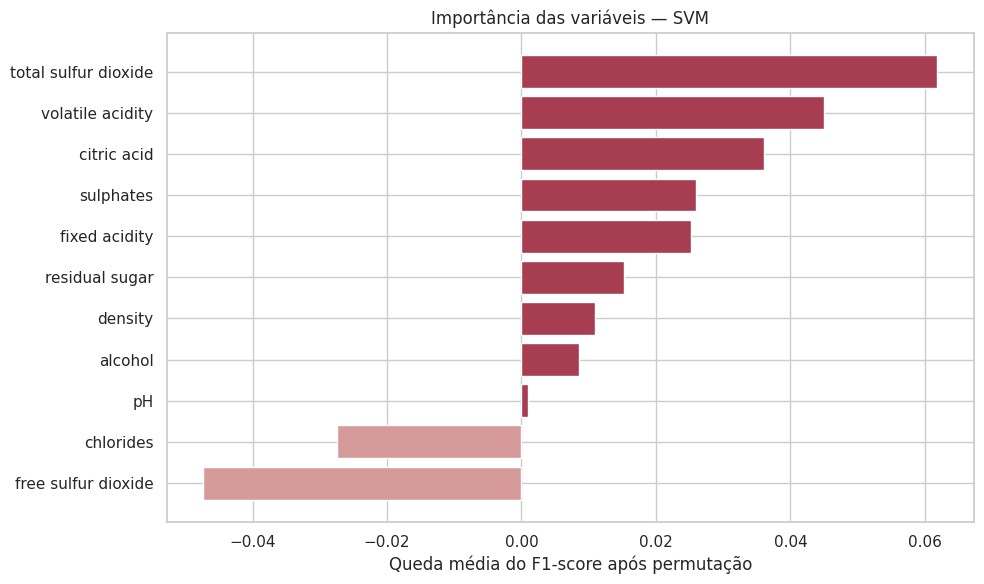

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone

X_subtreino, X_validacao, y_subtreino, y_validacao = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

modelo_interpretacao = clone(modelo_selecionado)

modelo_interpretacao.fit(
    X_subtreino,
    y_subtreino
)

importancias = permutation_importance(
    modelo_interpretacao,
    X_validacao,
    y_validacao,
    scoring="f1",
    n_repeats=20,
    random_state=42
)

tabela_importancia = pd.DataFrame({
    "Variável": X_validacao.columns,
    "Importância média": importancias.importances_mean,
    "Desvio-padrão": importancias.importances_std
}).sort_values(
    "Importância média",
    ascending=False
)

print("Modelo interpretado:", nome_modelo_selecionado)

display(tabela_importancia.round(4))

print('')

plt.figure(figsize=(10, 6))
cores = np.where(
    tabela_importancia["Importância média"] >= 0,
    '#A63D50',
    '#D69A9A'
)

plt.barh(
    tabela_importancia["Variável"],
    tabela_importancia["Importância média"],
    color=cores
)

plt.xlabel("Queda média do F1-score após permutação")
plt.title(
    f"Importância das variáveis — {nome_modelo_selecionado}"
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Interpretação da importância das características

A análise mostrou que o dióxido de enxofre total, a acidez volátil, o ácido cítrico e os sulfatos apresentaram as maiores importâncias médias para o modelo selecionado.

Isso significa que, durante a avaliação, alterar aleatoriamente os valores dessas características provocou uma redução no desempenho do modelo.

Entretanto, as diferenças entre as importâncias foram relativamente pequenas, e os resultados apresentaram variações entre as repetições.

Algumas características, como `chlorides` e `free sulfur dioxide`, apresentaram importância negativa. Isso indica que embaralhar seus valores não prejudicou o desempenho médio nessa avaliação específica.

Portanto, os resultados ajudam a compreender o comportamento do modelo, mas não permitem afirmar que determinadas características sejam sempre mais importantes ou que provoquem diretamente mudanças na qualidade do vinho.

In [ ]:
# Verificações finais de consistência

assert df.shape == (1143, 13), (
    "A base original possui formato inesperado."
)

assert df_vinhos.shape == (1018, 13), (
    "A base tratada deve conter 1.018 registros, "
    "11 características, quality e alta_qualidade."
)

assert df_vinhos.duplicated().sum() == 0, (
    "Ainda existem registros duplicados."
)

assert X.shape == (1018, 11), (
    "As variáveis preditoras possuem formato incorreto."
)

assert len(X_train) == 814
assert len(X_test) == 204

assert "quality" not in X.columns
assert "alta_qualidade" not in X.columns

assert comparacao_final.shape[0] == 4
assert tabela_importancia.shape[0] == 11

assert comparacao_final[
    ["Acurácia", "Precisão", "Recall", "F1-score"]
].notna().all().all(), (
    "Existem métricas ausentes."
)

padroes_treino = pd.MultiIndex.from_frame(X_train)
padroes_teste = pd.MultiIndex.from_frame(X_test)

assert not padroes_teste.isin(padroes_treino).any(), (
    "Foram encontrados padrões idênticos entre treino e teste."
)

print("Todas as verificações estruturais foram concluídas.")

Todas as verificações estruturais foram concluídas.


### Resumo dos resultados

Após a remoção dos registros duplicados, os modelos foram treinados com 814 vinhos e avaliados com 204 vinhos separados para teste.

O SVM foi selecionado por apresentar o melhor F1-score médio na validação cruzada.

Na avaliação final, o SVM otimizado identificou 74,07% dos vinhos de alta qualidade, mas apresentou precisão de 41,67%.

Isso significa que o modelo conseguiu encontrar boa parte dos vinhos dessa categoria, embora ainda tenha cometido uma quantidade importante de erros.

Os resultados indicam que a classificação automática pode apoiar a análise dos vinhos, mas precisa ser utilizada com cautela e complementada por avaliações especializadas.

# Conclusões e recomendações

## Conclusões

O objetivo deste projeto foi investigar se as características físico-químicas dos vinhos poderiam ser utilizadas para identificar aqueles classificados como de alta qualidade, considerando notas iguais ou superiores a 7.

Para isso, utilizamos uma base que continha inicialmente 1.143 registros. Após a identificação e remoção de 125 registros duplicados, trabalhamos com 1.018 vinhos, considerando 11 características físico-químicas.

### Principais descobertas da análise exploratória

A análise dos dados mostrou que algumas características apresentam associações com a qualidade dos vinhos.

O teor alcoólico apresentou uma associação positiva com a nota de qualidade, enquanto a acidez volátil apresentou uma associação negativa. Isso significa que, na base analisada, vinhos com maiores teores alcoólicos e menores níveis de acidez volátil tenderam a receber avaliações mais elevadas.

Entretanto, observamos que vinhos com notas diferentes podem apresentar características semelhantes. Por esse motivo, nenhuma dessas informações deve ser utilizada isoladamente para determinar a qualidade de um vinho.

Também identificamos uma diferença importante na quantidade de vinhos de cada categoria: apenas 13,46% dos registros foram classificados como de alta qualidade.

Essa distribuição representa um desafio para os modelos, pois eles precisam aprender a identificar uma categoria que aparece com menor frequência nos dados.

### Desenvolvimento e comparação dos modelos

Foram desenvolvidos dois modelos de classificação: K-Nearest Neighbors (KNN) e Support Vector Machine (SVM).

Inicialmente, treinamos versões básicas dos dois modelos. Depois, testamos diferentes configurações para buscar melhores resultados.

Para escolher essas configurações, utilizamos validação cruzada com cinco divisões dos dados de treinamento. O principal critério de comparação foi o F1-score, que considera tanto a capacidade de identificar os vinhos de alta qualidade quanto a quantidade de classificações positivas incorretas.

Na validação cruzada, o SVM apresentou o melhor F1-score médio, de **50,63%**, enquanto o KNN obteve **44,17%**.

Por esse motivo, o SVM foi selecionado como o modelo principal do projeto.

### Resultados da avaliação final

Na avaliação com os dados de teste, o SVM otimizado apresentou:

- **Acurácia:** 82,84%.
- **Precisão:** 41,67%.
- **Recall:** 74,07%.
- **F1-score:** 53,33%.

O modelo identificou corretamente **20 dos 27 vinhos de alta qualidade** presentes no conjunto de teste.

Por outro lado, deixou de identificar 7 vinhos dessa categoria e classificou incorretamente 28 vinhos de baixa/média qualidade como sendo de alta qualidade.

Esses resultados mostram que o modelo conseguiu identificar uma parcela maior dos vinhos de alta qualidade, mas ainda apresentou uma quantidade considerável de classificações incorretas.

O KNN otimizado, por sua vez, alcançou acurácia de 89,22%, precisão de 63,16%, recall de 44,44% e F1-score de 52,17%.

Isso demonstra que o KNN produziu menos classificações positivas incorretas, mas deixou de identificar mais vinhos de alta qualidade.

Portanto, não existe um modelo que tenha apresentado os melhores resultados em todas as medidas.

A escolha do SVM está relacionada ao objetivo de identificar o maior número possível de vinhos potencialmente de alta qualidade, mesmo que alguns precisem ser descartados posteriormente por uma avaliação especializada.

### Características mais importantes para as previsões

Também investigamos quais características físico-químicas tiveram maior influência no desempenho do SVM selecionado.

As quatro variáveis com maior importância média foram:

- **Dióxido de enxofre total (`total sulfur dioxide`):** 0,0619.
- **Acidez volátil (`volatile acidity`):** 0,0449.
- **Ácido cítrico (`citric acid`):** 0,0361.
- **Sulfatos (`sulphates`):** 0,0260.

Esses resultados indicam que o modelo utilizou informações dessas características para realizar suas classificações.

Entretanto, as diferenças de importância foram relativamente pequenas e apresentaram variações entre as repetições da análise. Por isso, não podemos afirmar que essas quatro características sejam definitivamente as mais importantes em qualquer conjunto de vinhos.

Também é importante destacar que uma característica relevante para as previsões não necessariamente causa aumento ou redução da qualidade do vinho.

### Como o modelo poderia ajudar uma vinícola?

O modelo desenvolvido pode ser considerado uma ferramenta inicial de apoio à identificação de vinhos que mereçam uma avaliação mais detalhada.

Por exemplo, uma vinícola poderia utilizar suas previsões como uma etapa complementar de triagem, encaminhando os vinhos classificados como de alta qualidade para uma análise especializada.

Essa aplicação seria compatível com o resultado do SVM, que conseguiu identificar aproximadamente três em cada quatro vinhos de alta qualidade no conjunto de teste.

Entretanto, como o modelo também apresentou falsos positivos, suas previsões não devem ser utilizadas isoladamente para definir a qualidade final ou o valor comercial de um produto.

### Limitações e possibilidades de melhoria

O estudo apresenta algumas limitações:

- A quantidade de vinhos de alta qualidade é relativamente pequena, dificultando o aprendizado e a avaliação dessa categoria.
- A exclusão dos registros duplicados foi uma decisão de preparação dos dados, sem confirmação de que todas as repetições representavam erros.
- O desempenho foi avaliado em um conjunto de teste relativamente pequeno, com apenas 27 vinhos de alta qualidade.
- Os modelos ainda cometem erros que podem influenciar sua aplicação prática.
- Os resultados foram obtidos com uma base específica e precisam ser confirmados com novos dados antes de qualquer utilização operacional.

Como continuidade, seria interessante avaliar os modelos em novas amostras, investigar formas de reduzir as classificações incorretas e verificar se o desempenho se mantém em diferentes situações.

### Considerações finais

O projeto demonstrou que técnicas de Machine Learning podem ajudar a identificar padrões relacionados à qualidade dos vinhos a partir de suas características físico-químicas.

A comparação entre KNN e SVM mostrou a importância de analisar diferentes medidas de desempenho, especialmente quando existe desequilíbrio entre as categorias.

Embora o SVM otimizado tenha apresentado o melhor resultado segundo o critério de seleção estabelecido, seu desempenho ainda possui limitações importantes.

Assim, concluímos que a solução desenvolvida apresenta potencial como ferramenta de apoio à análise da qualidade dos vinhos, mas **não está pronta para substituir avaliações especializadas ou tomar decisões de produção de forma automática**.

O principal resultado do projeto foi demonstrar como a preparação dos dados, a análise exploratória e a comparação de modelos podem contribuir para uma compreensão mais completa de um problema real.

In [ ]:
# Salvar as tabelas de resultados em arquivos CSV
comparacao_final.round(4).to_csv('metricas_modelos.csv', index=False)
tabela_importancia.round(4).to_csv('importancia_variaveis.csv', index=False)
outlier_summary.round(2).to_csv('outliers_iqr.csv', index=False)
df_vinhos_por_qualidade.to_csv('vinhos_por_nota.csv')

print('Tabelas salvas!')

Tabelas salvas!
